# INDIVIDUAL PROJECT - AI & APPLICATIONS (M504)

# Student Number - GH1050946

# Student Name - AGABA JOSHUA

# Table Of Contents

1. Business Context
2. Data Exploration
3. Data Preprocessing
4. Explanatory Data Analysis
5. Final discussion and conclusion

Data source URL: https://www.kaggle.com/datasets/anandshaw2001/netflix-movies-and-tv-shows/data

## 1. Business Context

Netflix is a global streaming platform that offers access to variety of film content for a tailored price.

The Netflix data provided within this dataset is mostly categorical, with interesting metadata provided for the title category such as its genre, country it originates from, type of film whether it is a movie of tv-show, year it was released etcetera.

As the data scientist that has been consulted, i am going to build an explanatory data analysis pipeline that will be able to answer business questions hereby enabling the Netflix budget and production team to make informed decisions on future resource allocation in order to yield significant return on investment.

### Importing the necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### Reading the Dataset

In [2]:
df_netflix = pd.read_csv("/content/netflix_titles.csv")

df_netflix.head(3)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...


## 2. Data Exploration

In [3]:
df_netflix.shape

(8807, 12)

So know we are dealing with 8,807 rows and 12 columns.

In [4]:
df_netflix.dtypes

,0
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object


We are dealing with mostly categorical values.

In [5]:
# This code checks for this missing values

print("Total number of missing values:", df_netflix.isna().sum().sum())
df_netflix.isna().sum()

Total number of missing values: 4307


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


We have identified that the dataset has a total number of 4,307 missing values.

The fields with the most missing values are the director, cast and country. These will be effectively data without negatively affecting the dataset.

## 3. Data Preprocessing

In [6]:
# Handling the missing values for the director, cast, country by filling the missing values with 'Unknown'
# This is because we cannot randomly fill the missing values since that would make the data inaccurate

df_netflix["director"] = df_netflix["director"].fillna("Unknown")
df_netflix["cast"] = df_netflix["cast"].fillna("Unknown")
df_netflix["country"] = df_netflix["country"].fillna("Unknown")

df_netflix.isna().sum()


,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,4
duration,3


In [7]:
# To deal with the rating that has only 4 missing values, we can use the mode of the rating
# The mode of this category will give us the most possible rating to appear

df_netflix["rating"] = df_netflix["rating"].fillna(df_netflix["rating"].mode()[0])

df_netflix.isna().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,3


In [8]:
# To deal with date added, we shall first convert it into an understandable date time format for python
# We shall also add two new columns from this dataset that can give us more insight into our dataset

df_netflix["date_added"] = pd.to_datetime(df_netflix["date_added"], errors="coerce")

df_netflix["year_added"] = df_netflix["date_added"].dt.year
df_netflix["month_added"] = df_netflix["date_added"].dt.month

df_netflix.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",Unknown,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...,2021.0,9.0
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",Unknown,2021-09-24,2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...,2021.0,9.0
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s...",2021.0,9.0
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,2021-09-24,2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...,2021.0,9.0
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,2021-09-24,2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...,2021.0,9.0


For both date_added and duration, we can choose to drop the rows with the missing values since any modifications would make the data inaccurate.

In [9]:
# Dropping the missing values

df_netflix = df_netflix.dropna(subset=["date_added", "duration"])

df_netflix.isna().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


The dataset is now cleaned and we have no missing values.

In [10]:
# Checking for any duplicates within the netflix dataset

print("Total number of duplicated:", df_netflix.duplicated().sum())
df_netflix.duplicated().sum()

Total number of duplicated: 0


np.int64(0)

There are no duplicates in the dataset. So we can conclude that the dataset is now clean.

## 4. Explanatory Data Analysis

### Question 1: What is the most dominating content type between Movies and TV shows on Netflix?

Importance: This helps with efficient resource allocation when prioritizing future content.

<Axes: xlabel='type', ylabel='count'>

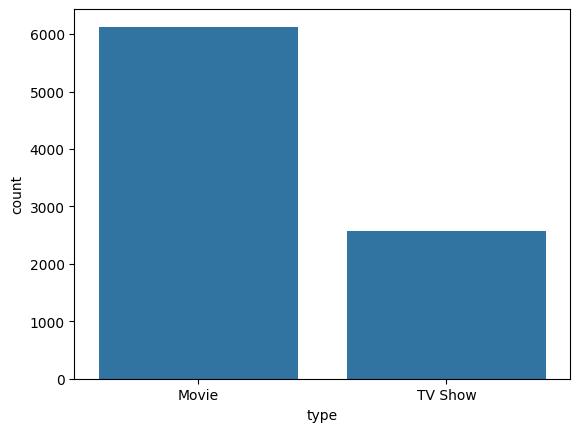

In [11]:
#This code is to find out the number of times the different values with the type cplumn appear
df_netflix["type"].value_counts()

# This will create a bar chart for the type column using the seaborn python package we imported
sns.barplot(df_netflix["type"].value_counts())

In [12]:
# This is to create a pie chart showing the percentage distribtion of the Netflix type category

fig = px.pie(df_netflix, names="type", title="Percentage Distribution of Netflix Type category")
fig.show()


Movies are the most dominating content type in Netflix, controlling a significant 70% as shown in the visualization above.

### Question 2: Which countries are the primary providers of Netflix content?

Importance: This helps determine which countries to focus on when considering strategic partnerships

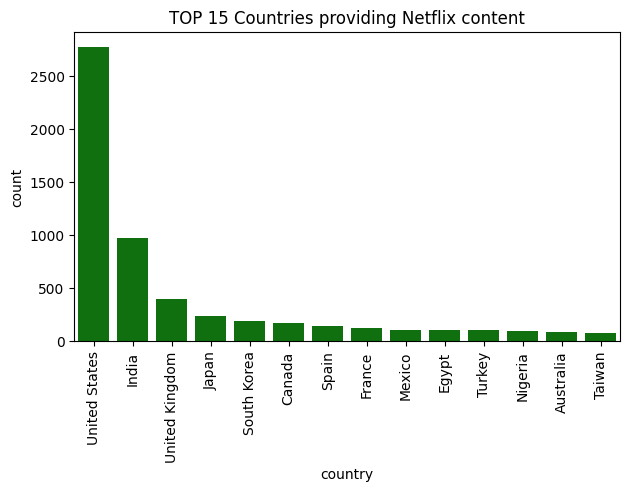

In [13]:
# This code shows us the top 15 countries for Netflix content

Netflix_Top_Countries = df_netflix["country"].value_counts().head(15).drop("Unknown")

sns.barplot(Netflix_Top_Countries, color="green")
plt.xticks(rotation=90)
plt.tight_layout()
plt.title("TOP 15 Countries providing Netflix content")
plt.show()

The visualization shows us that the country providing the highest Netflix content is the USA followed by India, and so on.

### Question 3: Who are the most influential directors on Netflix?

Importance: Helps Netflix identify potential future contract offers

Text(0.5, 1.0, 'TOP 10 Most Influential Directors')

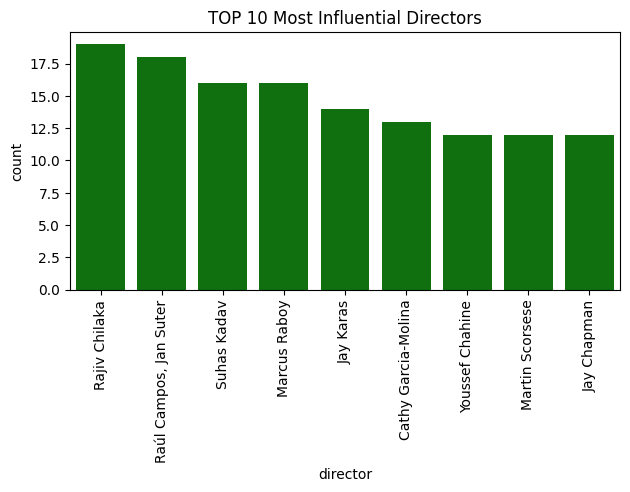

In [15]:

Most_influential_Director = df_netflix["director"].value_counts().head(10).drop("Unknown")

sns.barplot(Most_influential_Director, color="green")
plt.xticks(rotation=90)
plt.tight_layout()
plt.title("TOP 10 Most Influential Directors")

According to the visualization, it shows us that Rajic Chilaka is the most influential followed by Raúl and Jan, then Marcus and Jay and so on.

Netflix can prioritize their offers according to this list.

### Question 4: What content ratings are most popular within Netflix?

Importance: Helps Netflix understand its market segmentation in order to know how to prioritize resource allocation for future content.

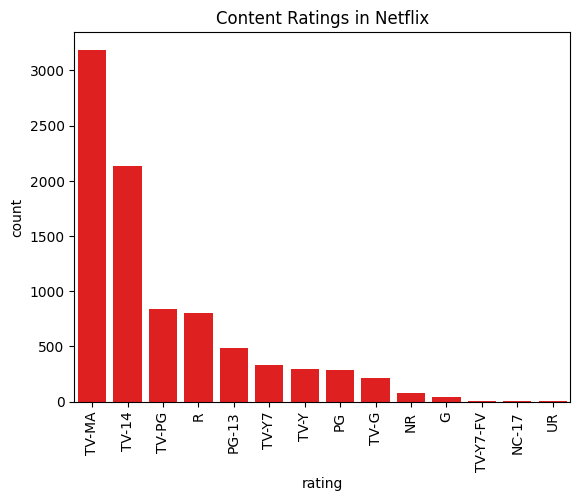

In [19]:
df_netflix["rating"].value_counts()

sns.barplot(df_netflix["rating"].value_counts(), color="red")
plt.xticks(rotation=90)
plt.title("Content Ratings in Netflix")
plt.show()

In [17]:
fig = px.pie(df_netflix, names="rating", title="Percentage Distribution of Netflix Rating category")
fig.show()

From the visualizations above, we can see that overall the Netflix content consumption is more adult and teenager oriented.

Netflix should focus its budget toward production of more adult friendly content in order to have guaranteed return on investment.

### Question 5: What are Netflix's top performing Genres?

Importance: This will help the budget and production team know where to focus the company resources.

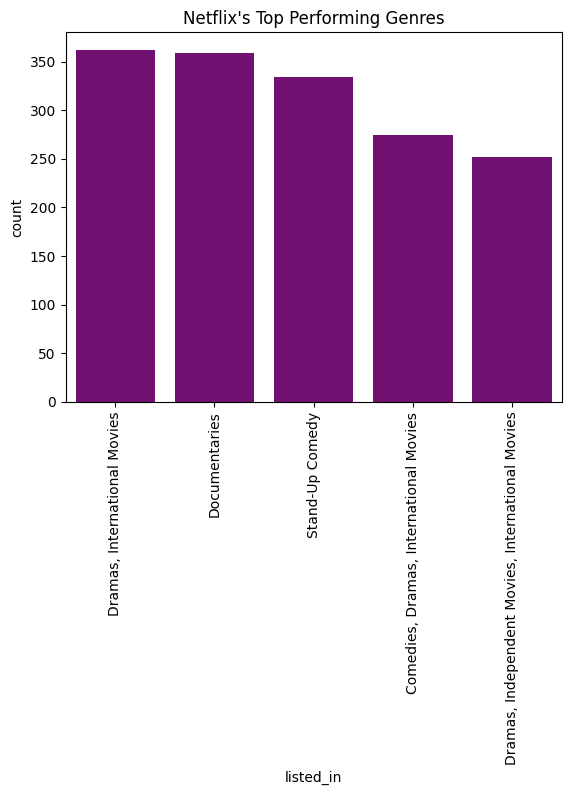

In [27]:
Top_5_Netflix_genres = df_netflix["listed_in"].value_counts().head()

sns.barplot(Top_5_Netflix_genres, color="purple")
plt.xticks(rotation=90)
plt.title("Netflix's Top Performing Genres")
plt.show()


In [28]:
fig = px.pie(Top_5_Netflix_genres, values=Top_5_Netflix_genres.values,
             names=Top_5_Netflix_genres.index,
             title="Percentage Distribution of the Netflix Genres"
)
fig.show()

From the visualization above, we can see that Netflix's most profitable genres are Dramas and Interntional movies, followed by Documentaries, Stand-Up Comedy and so on.

This also gives the production team on where not to focus company resources.

## 5. Final discussion and conclusion

### Data-driven reccomendations

1. Netflix should prioritze future  conent production to fit mature and teenager audiences in order to maximize return on investment.
2. Netflix should target its marketing campaigns towards countries that are underrepresented in regards to content production.


### Insights and implications

Netflix data highlights a strong market segmentation for movies preferrablely for adult and teenage audiences.

This can help Netflix structure its future projects to prioritize and deliver fully to market segmentation in order to maximize return on investment.

### Strengths

1. The pipeline effectively addresses the missing values where detected and does so without losing major valuable data.
2. The pipeline effectively visualizes the results for the iddentified business questions in a clear and understandable way for any user.

### Limitations

1. The missing values in the categories date_added and duration that had to be dropped may have a negative impact on the relationships within the dataset.
2. This dataset categories are limited and therefore more insight on how to better Netflix target customers cannot be determined.